In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use on_bad_lines='skip' to skip the malformed row near EOF after I recieved an error the first time
# Load data to dataframe for cleaning and analysis
traffic_data = pd.read_csv("export.csv", on_bad_lines='skip')
traffic_data.head()

/tmp/ipykernel_64316/1713167429.py:7: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  traffic_data = pd.read_csv("export.csv", on_bad_lines='skip')


,SeqID,Date Of Stop,Time Of Stop,Agency,SubAgency,Description,Location,Latitude,Longitude,Accident,...,Charge,Article,Contributed To Accident,Race,Gender,Driver City,Driver State,DL State,Arrest Type,Geolocation
0,8ca56a44-7e33-462d-8124-45ad80a35ebb,10/19/2026,18:38:00,MCP,Headquarters and Special Operations,PARKING WHERE PROHIBITED BY OFFICIAL SIGNS,ASPEN HILL SC,0.000000,0.000000,No,...,21-1003(aa),Transportation Article,False,HISPANIC,M,SEATTLE,WA,WA,A - Marked Patrol,"(0.0, 0.0)"
1,c2341716-38f5-4bd6-af71-bc1bf05766d4,10/19/2026,18:21:00,MCP,"2nd District, Bethesda",DRIVER FAILURE TO STOP AT STOP SIGN LINE,LELAND ST/ MAPLE AVE,38.984993,-77.084001,No,...,21-707(a),Transportation Article,False,WHITE,F,SILVER SPRING,MD,CA,A - Marked Patrol,"(38.984993, -77.084001)"
2,64d249de-26b8-4c8f-8865-92b67808b165,10/19/2026,18:11:00,MCP,"2nd District, Bethesda",DRIVER FAILURE TO STOP AT STOP SIGN LINE,LELAND ST/ MAPLE AVE,38.985466,-77.083832,No,...,21-707(a),Transportation Article,False,WHITE,M,BETHESDA,MD,MD,A - Marked Patrol,"(38.9854663333333, -77.0838318333333)"
3,9489a05d-6b42-475f-8d63-a5a6306d726a,10/19/2026,17:44:00,MCP,"3rd District, Silver Spring",DRIVER FAILURE TO STOP AT STEADY CIRCULAR RED ...,WB 15600 BLK OLD COLUMBIA PK,39.109927,-76.934930,No,...,21-202(h1),Transportation Article,False,HISPANIC,F,LAUREL,MD,MD,A - Marked Patrol,"(39.1099271666667, -76.93493)"
4,bc782dab-2eab-4d13-8c16-eed7171b080b,10/19/2026,17:44:00,MCP,"2nd District, Bethesda",DRIVER FAILURE TO OBEY PROPERLY PLACED TRAFFIC...,OLD GEORGETOWN AT TUCKERMAN LN,0.000000,0.000000,No,...,21-201(a1),Transportation Article,False,WHITE,F,SILVER SPRING,MD,MD,A - Marked Patrol,"(0.0, 0.0)"


In [ ]:
# check for missing values by column

traffic_data.isna().sum()

,0
SeqID,0
Date Of Stop,0
Time Of Stop,0
Agency,0
SubAgency,0
Description,10
Location,5
Latitude,0
Longitude,0
Accident,0


In [ ]:
# Check column data types to see if we need to adjust any of them
traffic_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2163268 entries, 0 to 2163267
Data columns (total 43 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   SeqID                    object 
 1   Date Of Stop             object 
 2   Time Of Stop             object 
 3   Agency                   object 
 4   SubAgency                object 
 5   Description              object 
 6   Location                 object 
 7   Latitude                 float64
 8   Longitude                float64
 9   Accident                 object 
 10  Belts                    object 
 11  Personal Injury          object 
 12  Property Damage          object 
 13  Fatal                    object 
 14  Commercial License       object 
 15  HAZMAT                   object 
 16  Commercial Vehicle       object 
 17  Alcohol                  object 
 18  Work Zone                object 
 19  Search Conducted         object 
 20  Search Disposition       object 
 21  Search O

# Data Cleaning

In [ ]:
# change date of stop column to actual date data type instead of object
traffic_data['Date Of Stop'] = pd.to_datetime(traffic_data['Date Of Stop'], errors='coerce')

# Traffic Violations by Season

## We will use the meteorological seasons

### Source: https://www.timeanddate.com/calendar/aboutseasons.html


Spring: March, April, May

Summer: June, July, August

Autumn (Fall): September, October, November

Winter: December, January, February

In [ ]:
# use .dt from pandas to extract month from date of stop
traffic_data['Month'] = traffic_data['Date Of Stop'].dt.month

# map month numbers to season mentioned above
def get_season(month):
    if pd.isna(month):
        return None
    if month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    elif month in [9, 10, 11]:
        return 'Autumn'
    else:
        return 'Winter'

# add season column using mappings
traffic_data['Season'] = traffic_data['Month'].apply(get_season)

# filter and make a dataframe to keep only unique SeqID entries
unique_stops = traffic_data.drop_duplicates(subset=['SeqID']).dropna(subset=['Season'])

# count number of stops by season
season_counts = unique_stops['Season'].value_counts()
display(season_counts.to_frame('Unique Stops'))

,Unique Stops
Season,
Spring,338998
Autumn,303152
Summer,297942
Winter,295239


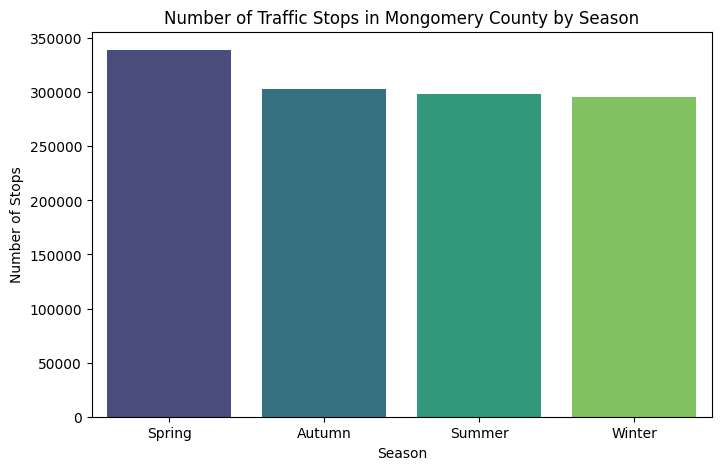

In [ ]:
# plot bar plot to visualize stops by season
plt.figure(figsize=(8, 5))
sns.barplot(x=season_counts.index, y=season_counts.values, palette='viridis', hue=season_counts.index, legend=False)
plt.title('Number of Traffic Stops in Mongomery County by Season')
plt.xlabel('Season')
plt.ylabel('Number of Stops')
plt.show()

# Traffic stops trend from 2012-2026

,Unique Stops
Year_Of_Stop,
2012,92096
2013,112125
2014,129892
2015,130362
2016,120276
2017,110239
2018,121096
2019,106081
2020,39415


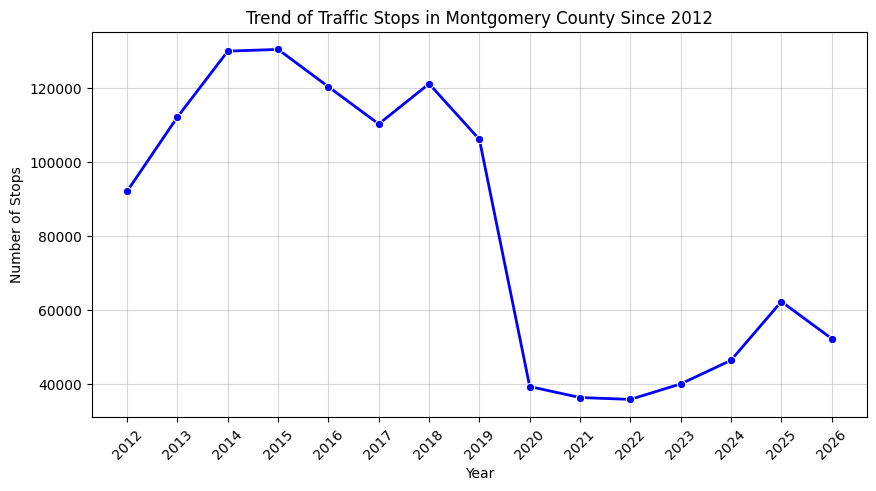

In [ ]:
# get year from date of stop column
traffic_data['Year_Of_Stop'] = traffic_data['Date Of Stop'].dt.year

# filter for unique stops using SeqID and years >= 2012
unique_stops_by_year = traffic_data.drop_duplicates(subset=['SeqID']).dropna(subset=['Year_Of_Stop'])
unique_stops_since_2012 = unique_stops_by_year[unique_stops_by_year['Year_Of_Stop'] >= 2012]

# count unique stops per year
yearly_counts = unique_stops_since_2012['Year_Of_Stop'].value_counts().sort_index()

# table of stops by year
display(yearly_counts.to_frame('Unique Stops'))

# plot line graph
plt.figure(figsize=(10, 5))
sns.lineplot(x=yearly_counts.index, y=yearly_counts.values, marker='o', color='b', linewidth=2)
plt.title('Trend of Traffic Stops in Montgomery County Since 2012')
plt.xlabel('Year')
plt.ylabel('Number of Stops')
plt.grid(True, alpha=0.5)
plt.xticks(yearly_counts.index, rotation=45)
plt.show()